# Влияние набора признаков на качество модели

Проверим, как меняется Average Precision Logistic Regression при исключении отдельных признаков и их групп.

Сначала рассмотрим коррелирующие экономические показатели, затем — признаки, доступность которых зависит от момента прогнозирования.

Все сравнения проводятся на Train с одинаковой кросс-валидацией и фиксированными гиперпараметрами. Test не используется.

## 1. Подготовка данных и исходная модель

Загрузим данные, воспроизведём Train/Test-разделение и исходную Logistic Regression с One-Hot Encoding.

Рассчитаем базовый Average Precision с помощью пятифолдовой кросс-валидации. Этот результат будем использовать для сравнения с упрощёнными конфигурациями.


In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt


import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.base import clone

project_root = Path.cwd().resolve()

if project_root.name == 'notebooks':
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Данные
df = pd.read_csv(
    project_root / 'data' / 'raw' / 'banking.csv'
)

X = df.drop(columns=['y', 'duration'])
y = df['y']

# То же разделение, что и в предыдущих ноутбуках
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Загружаем лучшую конфигурацию
model = joblib.load(
    project_root / 'models' / 'logistic_onehot.joblib'
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print('Размер Train:', X_train.shape)
print('Параметры модели:')
print(model.named_steps['model'].get_params()['C'])
print(model.named_steps['model'].get_params()['class_weight'])


Размер Train: (32950, 19)
Параметры модели:
10
None


In [2]:
baseline_scores = cross_val_score(
    clone(model),
    X_train,
    y_train,
    cv=cv,
    scoring='average_precision',
    n_jobs=2
)

print('AP по фолдам:', baseline_scores.round(4))
print('Средний AP:', round(baseline_scores.mean(), 4))
print('Стандартное отклонение:', round(baseline_scores.std(), 4))

AP по фолдам: [0.4551 0.4808 0.4564 0.4235 0.4678]
Средний AP: 0.4567
Стандартное отклонение: 0.019


## 2. Исключение `euribor3m`

Признаки `euribor3m` и `emp_var_rate` сильно коррелируют между собой (r = 0.972).

Проверим, изменится ли Average Precision после исключения `euribor3m`.

Оставим прежние гиперпараметры Logistic Regression и используем те же пять фолдов кросс-валидации.


In [3]:
# Копируем исходный пайплайн
model_no_euribor = clone(model)

# Получаем ColumnTransformer
columns = (
    model_no_euribor
    .named_steps['preprocessing']
    .named_steps['columns']
)

# Исключаем euribor3m из числовых признаков
columns.transformers = [
    (
        name,
        transformer,
        [col for col in feature_cols if col != 'euribor3m']
        if name == 'numeric' else feature_cols
    )
    for name, transformer, feature_cols in columns.transformers
]

# Повторяем кросс-валидацию
no_euribor_scores = cross_val_score(
    model_no_euribor,
    X_train,
    y_train,
    cv=cv,
    scoring='average_precision',
    n_jobs=2
)

# Сравнение
comparison = pd.DataFrame({
    'Baseline': baseline_scores,
    'Without euribor3m': no_euribor_scores
})

comparison['Difference'] = (
    comparison['Without euribor3m']
    - comparison['Baseline']
)

display(comparison.round(4))

print('Baseline AP:', round(baseline_scores.mean(), 4))
print('Без euribor3m:', round(no_euribor_scores.mean(), 4))
print('Разница:', round(comparison['Difference'].mean(), 4))


,Baseline,Without euribor3m,Difference
0,0.4551,0.4557,0.0006
1,0.4808,0.4811,0.0003
2,0.4564,0.4556,-0.0008
3,0.4235,0.4237,0.0002
4,0.4678,0.4670,-0.0008


Baseline AP: 0.4567
Без euribor3m: 0.4566
Разница: -0.0001


### Вывод

После исключения `euribor3m` средний CV AP практически не изменился: 0.4567 против 0.4566.

Это говорит о том, что при сохранении остальных признаков модель почти не теряет качество без `euribor3m`. Возможная причина — сильная корреляция с другими экономическими показателями.


## 3. Исключение `nr_employed`

Признак `nr_employed` сильно коррелирует с другими экономическими показателями.

Проверим, изменится ли качество Logistic Regression после его исключения. Остальные признаки и гиперпараметры оставим без изменений.


In [4]:
# Копия исходной модели
model_no_employed = clone(model)

columns = (
    model_no_employed
    .named_steps['preprocessing']
    .named_steps['columns']
)

# Исключаем только nr_employed
columns.transformers = [
    (
        name,
        transformer,
        [col for col in feature_cols if col != 'nr_employed']
        if name == 'numeric' else feature_cols
    )
    for name, transformer, feature_cols in columns.transformers
]

# Кросс-валидация
no_employed_scores = cross_val_score(
    model_no_employed,
    X_train,
    y_train,
    cv=cv,
    scoring='average_precision',
    n_jobs=2
)

# Сравнение с исходной моделью
comparison_employed = pd.DataFrame({
    'Baseline': baseline_scores,
    'Without nr_employed': no_employed_scores
})

comparison_employed['Difference'] = (
    comparison_employed['Without nr_employed']
    - comparison_employed['Baseline']
)

display(comparison_employed.round(4))

print('Baseline AP:', round(baseline_scores.mean(), 4))
print('Без nr_employed:', round(no_employed_scores.mean(), 4))
print('Разница:', round(comparison_employed['Difference'].mean(), 4))


,Baseline,Without nr_employed,Difference
0,0.4551,0.4529,-0.0022
1,0.4808,0.4811,0.0002
2,0.4564,0.4563,-0.0001
3,0.4235,0.4235,-0.0000
4,0.4678,0.4651,-0.0027


Baseline AP: 0.4567
Без nr_employed: 0.4558
Разница: -0.001


### Вывод

После исключения `nr_employed` средний CV AP снизился с 0.4567 до 0.4558. Разница составила около 0.001.

Как и в случае с `euribor3m`, удаление одного коррелирующего экономического признака почти не повлияло на качество модели.

Это может объясняться тем, что оставшиеся признаки содержат похожую информацию.


## 4. Одновременное исключение `euribor3m` и `nr_employed`

По отдельности исключение каждого из признаков почти не повлияло на Average Precision.

Проверим, сохранится ли качество модели, если убрать оба признака одновременно, оставив остальные экономические показатели.

Гиперпараметры и схема кросс-валидации останутся прежними.


In [5]:
# Копия исходной модели
model_no_two = clone(model)

# Признаки для исключения
drop_cols = {'euribor3m', 'nr_employed'}

columns = (
    model_no_two
    .named_steps['preprocessing']
    .named_steps['columns']
)

columns.transformers = [
    (
        name,
        transformer,
        [col for col in feature_cols if col not in drop_cols]
        if name == 'numeric' else feature_cols
    )
    for name, transformer, feature_cols in columns.transformers
]

# Кросс-валидация
no_two_scores = cross_val_score(
    model_no_two,
    X_train,
    y_train,
    cv=cv,
    scoring='average_precision',
    n_jobs=2
)

# Сравнение всех вариантов
comparison_all = pd.DataFrame({
    'Baseline': baseline_scores,
    'Without euribor3m': no_euribor_scores,
    'Without nr_employed': no_employed_scores,
    'Without both': no_two_scores
})

display(comparison_all.round(4))

print('\nСредний CV AP:')
print(comparison_all.mean().round(4))

print(
    '\nРазница с Baseline:',
    round(no_two_scores.mean() - baseline_scores.mean(), 4)
)


,Baseline,Without euribor3m,Without nr_employed,Without both
0,0.4551,0.4557,0.4529,0.4548
1,0.4808,0.4811,0.4811,0.4827
2,0.4564,0.4556,0.4563,0.4521
3,0.4235,0.4237,0.4235,0.4207
4,0.4678,0.4670,0.4651,0.4647



Средний CV AP:
Baseline               0.4567
Without euribor3m      0.4566
Without nr_employed    0.4558
Without both           0.4550
dtype: float64

Разница с Baseline: -0.0017


### Вывод

При одновременном исключении `euribor3m` и `nr_employed` средний CV AP снизился с 0.4567 до 0.4550 (разница −0.0017).

Несмотря на высокую корреляцию удалённых признаков с `emp_var_rate`, качество модели почти сохранилось.

Это позволяет предположить, что значительная часть информации из исключённых признаков уже содержится в оставшихся экономических показателях.

Однако небольшой размер разницы не доказывает эквивалентность моделей. Результат относится к текущей выборке, схеме кросс-валидации и фиксированным гиперпараметрам.


## 5. Сокращение экономических признаков до двух

В эксперименте с Permutation Importance наиболее важными оказались `emp_var_rate` и `cons_price_idx`.

Проверим, насколько изменится качество модели, если из пяти экономических показателей оставить только эти два.

Для этого исключим `euribor3m`, `nr_employed` и `cons_conf_idx`, сохранив остальные признаки и гиперпараметры.


In [6]:
# Копия исходной модели
model_two_economic = clone(model)

drop_cols = {
    'euribor3m',
    'nr_employed',
    'cons_conf_idx'
}

columns = (
    model_two_economic
    .named_steps['preprocessing']
    .named_steps['columns']
)

columns.transformers = [
    (
        name,
        transformer,
        [col for col in feature_cols if col not in drop_cols]
        if name == 'numeric' else feature_cols
    )
    for name, transformer, feature_cols in columns.transformers
]

# Кросс-валидация
two_economic_scores = cross_val_score(
    model_two_economic,
    X_train,
    y_train,
    cv=cv,
    scoring='average_precision',
    n_jobs=2
)

# Сравнение
comparison_economic = pd.DataFrame({
    'Baseline': baseline_scores,
    'Without both': no_two_scores,
    'Two economic features': two_economic_scores
})

display(comparison_economic.round(4))

print('\nСредний CV AP:')
print(comparison_economic.mean().round(4))

print(
    '\nРазница с Baseline:',
    round(
        two_economic_scores.mean()
        - baseline_scores.mean(),
        4
    )
)


,Baseline,Without both,Two economic features
0,0.4551,0.4548,0.4523
1,0.4808,0.4827,0.4756
2,0.4564,0.4521,0.4539
3,0.4235,0.4207,0.4229
4,0.4678,0.4647,0.4584



Средний CV AP:
Baseline                 0.4567
Without both             0.4550
Two economic features    0.4526
dtype: float64

Разница с Baseline: -0.0041


### Вывод

После исключения трёх экономических признаков средний CV AP снизился с 0.4567 до 0.4526 (разница −0.0041).

Таким образом, модель сохранила большую часть качества, используя только `emp_var_rate` и `cons_price_idx` из пяти экономических показателей.

Результат предполагает, что часть экономических признаков содержит избыточную информацию. Однако исключённые признаки всё же могут быть полезны, а небольшая разница AP не доказывает эквивалентность конфигураций.


## 6. Исключение всех экономических признаков

В предыдущих экспериментах удаление отдельных экономических показателей приводило к небольшому снижению Average Precision.

Теперь исключим все пять экономических признаков и повторно обучим модель.

Так мы сможем оценить, насколько полезна экономическая информация для прогнозирования при сохранении остальных признаков.


In [7]:
# Все экономические признаки
economic_cols = {
    'emp_var_rate',
    'cons_price_idx',
    'cons_conf_idx',
    'euribor3m',
    'nr_employed'
}

# Копируем исходную модель
model_no_economic = clone(model)

columns = (
    model_no_economic
    .named_steps['preprocessing']
    .named_steps['columns']
)

# Исключаем все экономические показатели
columns.transformers = [
    (
        name,
        transformer,
        [col for col in feature_cols if col not in economic_cols]
        if name == 'numeric' else feature_cols
    )
    for name, transformer, feature_cols in columns.transformers
]

# Одинаковая кросс-валидация
no_economic_scores = cross_val_score(
    model_no_economic,
    X_train,
    y_train,
    cv=cv,
    scoring='average_precision',
    n_jobs=2
)

# Сравнение
comparison_final = pd.DataFrame({
    'Baseline': baseline_scores,
    'Two economic features': two_economic_scores,
    'Without economic features': no_economic_scores
})

display(comparison_final.round(4))

print('\nСредний CV AP:')
print(comparison_final.mean().round(4))

print(
    '\nРазница с Baseline:',
    round(
        no_economic_scores.mean()
        - baseline_scores.mean(),
        4
    )
)


,Baseline,Two economic features,Without economic features
0,0.4551,0.4523,0.4133
1,0.4808,0.4756,0.4070
2,0.4564,0.4539,0.3887
3,0.4235,0.4229,0.3802
4,0.4678,0.4584,0.4195



Средний CV AP:
Baseline                     0.4567
Two economic features        0.4526
Without economic features    0.4018
dtype: float64

Разница с Baseline: -0.055


### Вывод

После исключения всех пяти экономических показателей средний CV AP снизился с 0.4567 до 0.4018. Разница составила −0.0550.

Это значительно больше, чем при исключении отдельных экономических признаков или сокращении их количества до двух.

Результат показывает, что экономические данные в целом содержат полезную для прогнозирования информацию. При этом часть показателей, вероятно, дублирует информацию друг друга.

В отличие от Permutation Importance, здесь модель обучается заново без исключённых признаков, поэтому может перераспределять их вклад на оставшиеся переменные.


## 7. Сравнение результатов

Соберём результаты всех экспериментов в одну таблицу и сравним средний Average Precision.

Все конфигурации оценивались на одинаковых пяти фолдах с фиксированными гиперпараметрами Logistic Regression.


In [8]:
# Сводная таблица всех экспериментов
all_scores = pd.DataFrame({
    'Все признаки': baseline_scores,
    'Без euribor3m': no_euribor_scores,
    'Без nr_employed': no_employed_scores,
    'Без обоих': no_two_scores,
    'Только 2 экономических': two_economic_scores,
    'Без экономических': no_economic_scores
})

summary = pd.DataFrame({
    'Mean AP': all_scores.mean(),
    'Std AP': all_scores.std(ddof=1),
    'AP Difference': all_scores.mean() - baseline_scores.mean()
})

display(summary.round(4))


,Mean AP,Std AP,AP Difference
Все признаки,0.4567,0.0213,0.0000
Без euribor3m,0.4566,0.0212,-0.0001
Без nr_employed,0.4558,0.0211,-0.0010
Без обоих,0.4550,0.0226,-0.0017
Только 2 экономических,0.4526,0.0190,-0.0041
Без экономических,0.4018,0.0167,-0.0550


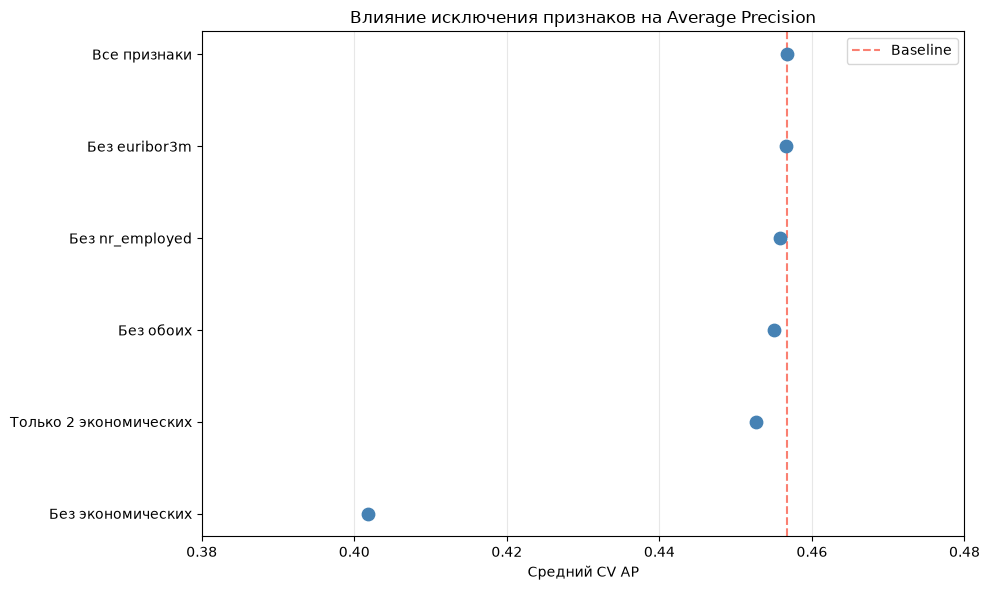

In [9]:
# Сортируем модели по AP
plot_data = summary.sort_values('Mean AP')

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    plot_data['Mean AP'],
    plot_data.index,
    color='steelblue',
    s=80,
    zorder=3
)

# Уровень исходной модели
ax.axvline(
    baseline_scores.mean(),
    color='salmon',
    linestyle='--',
    label='Baseline'
)

ax.set_title('Влияние исключения признаков на Average Precision')
ax.set_xlabel('Средний CV AP')
ax.set_ylabel('')

# Увеличиваем масштаб, чтобы различия были заметнее
ax.set_xlim(0.38, 0.48)
ax.grid(axis='x', alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


## 8. Доступность признаков перед звонком

В основной модели используются признаки, связанные с текущим контактом. Их доступность до звонка зависит от бизнес-процесса и не подтверждена исходными данными. Проверим, насколько качество модели зависит от этой информации.

Сравним три конфигурации:

- Исходная модель — все признаки, кроме `duration`.
- Без контекста звонка — исключены `contact`, `month`, `day_of_week`.
- Консервативная — дополнительно исключён `campaign`.

Все модели оценим на одинаковых CV-фолдах Train с исходными гиперпараметрами. Test не используем.

In [10]:
# Наборы исключаемых признаков
contact_variants = {
    'Baseline': set(),
    'Without contact context': {
        'contact', 'month', 'day_of_week'
    },
    'Without context and campaign': {
        'contact', 'month', 'day_of_week', 'campaign'
    }
}

# Используем уже рассчитанный baseline
contact_results = {
    'Baseline': baseline_scores
}

for name, excluded_cols in contact_variants.items():
    if name == 'Baseline':
        continue

    # Копируем исходную модель
    variant_model = clone(model)

    columns = (
        variant_model
        .named_steps['preprocessing']
        .named_steps['columns']
    )

    # Убираем признаки из соответствующих преобразований
    new_transformers = [
        (
            transformer_name,
            transformer,
            [
                col for col in feature_cols
                if col not in excluded_cols
            ]
        )
        for transformer_name, transformer, feature_cols
        in columns.transformers
    ]

    columns.set_params(transformers=new_transformers)

    # Оцениваем на тех же пяти фолдах
    scores = cross_val_score(
        variant_model,
        X_train,
        y_train,
        cv=cv,
        scoring='average_precision',
        n_jobs=2
    )

    contact_results[name] = scores

# AP на отдельных фолдах
contact_folds = pd.DataFrame(contact_results)

display(contact_folds.round(4))

# Сводная таблица
contact_summary = pd.DataFrame({
    'Mean AP': contact_folds.mean(),
    'Std AP': contact_folds.std(ddof=1),
    'AP Difference': (
        contact_folds.mean() - baseline_scores.mean()
    )
})

display(contact_summary.round(4))


,Baseline,Without contact context,Without context and campaign
0,0.4551,0.4338,0.4325
1,0.4808,0.4570,0.4541
2,0.4564,0.4330,0.4288
3,0.4235,0.4004,0.3984
4,0.4678,0.4488,0.4468


,Mean AP,Std AP,AP Difference
Baseline,0.4567,0.0213,0.0000
Without contact context,0.4346,0.0217,-0.0221
Without context and campaign,0.4321,0.0215,-0.0246


### Вывод

Без `contact`, `month` и `day_of_week` средний CV AP снизился с 0.4567 до 0.4346. Дополнительное исключение `campaign` уменьшило AP до 0.4321.

Контекст звонка влияет на качество модели, но эксперимент не позволяет установить, были ли эти признаки доступны до звонка.

## 9. Итоги

Исключение отдельных коррелирующих экономических признаков почти не повлияло на качество модели. При удалении всех пяти экономических показателей средний CV AP снизился с 0.4567 до 0.4018.

Исключение признаков текущего звонка также ухудшило качество, но менее значительно.

### Ограничения

Все эксперименты проводились на Train с фиксированными гиперпараметрами. Повторный подбор параметров для сокращённых моделей не выполнялся.

Результаты носят исследовательский характер и не подтверждают эквивалентность конфигураций. Доступность признаков перед звонком требует отдельной проверки.